# Lab 3 - Task 6: VaR Comparison and Scenario Analysis (IndusInd Bank, `INDUSINDBK.NS`)

**Part A** puts the one-day VaR estimates from Tasks 3-5 into one table and compares them. **Part B** builds a two-dimensional scenario table for the 95% parametric VaR based on historical volatility.

**Conventions (same as Tasks 3-5):** simple daily returns in decimal form, the most recent 200 trading days as the VaR sample, daily (not annualised) volatility, VaR shown as a positive loss (0.032 = a 3.2% one-day loss).

To keep this notebook self-contained, the Task 3-5 estimates are recomputed here with the same code and settings. The data end date is fixed so that the last return is **12 Nov 2026**, the same sample as in Tasks 3-5.

Short explanations sit next to the code. The broader interpretation is in the accompanying Word report.

In [1]:
%pip install numpy pandas matplotlib scipy yfinance arch -q

Note: you may need to restart the kernel to use updated packages.


## 1. Setup and data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import yfinance as yf
from scipy import stats
from arch import arch_model

ticker      = "INDUSINDBK.NS"
start_date  = "2020-06-01"
end_date    = "2026-11-13"     # exclusive -> last return 12 Nov 2026, same sample as Tasks 3-5
var_window  = 200              # most recent 200 daily returns
conf_levels = [0.90, 0.95, 0.99]
lam         = 0.94             # EWMA decay (Task 4 cross-check)
n_sims      = 100_000          # Monte Carlo draws (Task 5)
seed        = 42

# chart colours: fixed categorical order, one colour per method
C = {"hs": "#2a78d6", "ph": "#eb6834", "pg": "#1baf7a", "mc": "#eda100"}

In [3]:
data = yf.download(ticker, start=start_date, end=end_date, auto_adjust=True, progress=False)
data = data[data["Volume"].squeeze() > 0]          # drop zero-volume (stale) days, as in Task 1

price       = data["Close"].squeeze()
returns     = price.pct_change().dropna()           # simple daily returns
var_returns = returns.iloc[-var_window:]            # 200-day VaR sample

print(f"Long sample : {returns.index[0].date()} to {returns.index[-1].date()} ({len(returns)} returns)")
print(f"VaR sample  : {var_returns.index[0].date()} to {var_returns.index[-1].date()} ({len(var_returns)} returns)")

Long sample : 2020-06-02 to 2026-11-12 (1597 returns)
VaR sample  : 2026-01-20 to 2026-11-12 (200 returns)


# Part A: Comparison of VaR Methods

## 2. Recompute the Task 3-5 estimates

Each method uses the same 200 returns. They differ only in **how the loss distribution is built**:

| Method | Volatility input | Distribution of returns |
|---|---|---|
| Historical simulation (Task 3) | none (uses the returns directly) | the 200 observed returns |
| Parametric, historical volatility (Task 4) | 200-day sample std. dev. | normal |
| Parametric, GARCH(1,1) (Task 4) | one-day-ahead GARCH forecast | normal |
| Monte Carlo (Task 5) | 200-day sample std. dev. | standardised Student-t, $\nu$ by MLE |

Parametric VaR: $\text{VaR}_c = z_c\,\sigma_d - \mu_d$. The same $\mu_d$ (200-day mean) is used in every parametric and Monte Carlo row.

In [4]:
# Task 3 - historical simulation: minus the 10th / 5th / 1st percentile of the 200 returns
hs_var = {c: -np.percentile(var_returns, 100 * (1 - c), method="linear") for c in conf_levels}

# Task 4 - parametric (normal) VaR with two volatility inputs
mu_d       = var_returns.mean()
sigma_hist = var_returns.std()                                   # ddof = 1

garch_res   = arch_model(returns * 100, mean="Constant", vol="GARCH", p=1, q=1,
                         dist="normal", rescale=False).fit(disp="off")
sigma_garch = np.sqrt(garch_res.forecast(horizon=1, reindex=False).variance.values[-1, 0]) / 100
sigma_ewma  = np.sqrt(returns.pow(2).ewm(alpha=1 - lam, adjust=False).mean().iloc[-1])

def parametric_var(mu, sigma, conf):
    return stats.norm.ppf(conf) * sigma - mu                     # positive = loss

ph_var = {c: parametric_var(mu_d, sigma_hist,  c) for c in conf_levels}
pg_var = {c: parametric_var(mu_d, sigma_garch, c) for c in conf_levels}
pe_var = {c: parametric_var(mu_d, sigma_ewma,  c) for c in conf_levels}

# Task 5 - Monte Carlo with a standardised Student-t (nu by MLE, clipped to [3, 30])
nu = float(np.clip(stats.t.fit(var_returns * 100)[0], 3, 30))
rng   = np.random.default_rng(seed)
sim_t = mu_d + sigma_hist * rng.standard_t(nu, size=n_sims) / np.sqrt(nu / (nu - 2))
rng   = np.random.default_rng(seed)
sim_n = mu_d + sigma_hist * rng.standard_normal(n_sims)
mc_t_var = {c: -np.percentile(sim_t, 100 * (1 - c)) for c in conf_levels}
mc_n_var = {c: -np.percentile(sim_n, 100 * (1 - c)) for c in conf_levels}

print(f"mu_d = {mu_d:.6f} | sigma (200d) = {sigma_hist:.6f} | sigma GARCH = {sigma_garch:.6f} | "
      f"sigma EWMA = {sigma_ewma:.6f} | nu = {nu:.2f}")

mu_d = 0.000106 | sigma (200d) = 0.019820 | sigma GARCH = 0.026474 | sigma EWMA = 0.021533 | nu = 5.61


## 3. Comparison table

The four required rows. For the EWMA/GARCH row, Task 4 used **GARCH(1,1)** as the main estimate; EWMA was only a cross-check, so it appears in the supplementary table below together with the normal Monte Carlo benchmark.

In [5]:
methods = {
    "Historical Simulation":                        hs_var,
    "Parametric - Historical Volatility (200d)":    ph_var,
    "Parametric - GARCH(1,1)":                      pg_var,
    f"Monte Carlo Simulation (Student-t, nu={nu:.1f})": mc_t_var,
}
cols = [f"{int(c*100)}% VaR" for c in conf_levels]
comparison = pd.DataFrame([[m[c] for c in conf_levels] for m in methods.values()],
                          index=list(methods.keys()), columns=cols)
comparison.index.name = "Method"

(comparison * 100).style.format("{:.3f}%").set_caption("One-day VaR, IndusInd Bank (% of position)")

,90% VaR,95% VaR,99% VaR
Method,,,
Historical Simulation,2.362%,3.444%,5.061%
Parametric - Historical Volatility (200d),2.529%,3.249%,4.600%
"Parametric - GARCH(1,1)",3.382%,4.344%,6.148%
"Monte Carlo Simulation (Student-t, nu=5.6)",2.292%,3.107%,5.130%


In [6]:
supplementary = pd.DataFrame(
    [[pe_var[c] for c in conf_levels], [mc_n_var[c] for c in conf_levels]],
    index=["Parametric - EWMA (0.94), cross-check", "Monte Carlo - Normal, benchmark"], columns=cols)
(supplementary * 100).style.format("{:.3f}%").set_caption("Supplementary estimates (not in the required table)")

,90% VaR,95% VaR,99% VaR
"Parametric - EWMA (0.94), cross-check",2.749%,3.531%,4.999%
"Monte Carlo - Normal, benchmark",2.546%,3.276%,4.634%


## 4. Visual comparison and relative size

The table below the chart expresses every estimate relative to historical simulation, which makes no distributional assumption and is therefore a natural reference point.

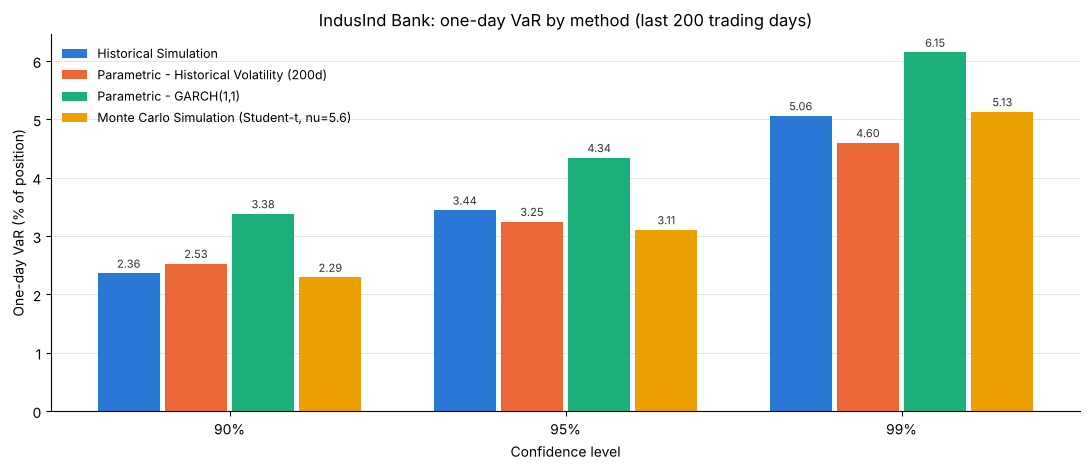

,90% VaR,95% VaR,99% VaR
Method,,,
Historical Simulation,1.00x,1.00x,1.00x
Parametric - Historical Volatility (200d),1.07x,0.94x,0.91x
"Parametric - GARCH(1,1)",1.43x,1.26x,1.21x
"Monte Carlo Simulation (Student-t, nu=5.6)",0.97x,0.90x,1.01x


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x, w = np.arange(len(conf_levels)), 0.2
for i, (name, key) in enumerate(zip(comparison.index, C)):
    vals = comparison.loc[name].values * 100
    bars = ax.bar(x + (i - 1.5) * w, vals, w * 0.92, color=C[key], label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center", va="bottom", fontsize=8, color="#333333")
ax.set_xticks(x, [f"{int(c*100)}%" for c in conf_levels])
ax.set_xlabel("Confidence level"); ax.set_ylabel("One-day VaR (% of position)")
ax.set_title("IndusInd Bank: one-day VaR by method (last 200 trading days)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e1e0d9", lw=0.6); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("task6_var_comparison.png", dpi=150); plt.show()

ratio = comparison.div(comparison.loc["Historical Simulation"], axis=1)
ratio.style.format("{:.2f}x").set_caption("VaR relative to historical simulation")

## 5. Why the estimates differ: implied multipliers and tail shape

Writing every estimate as $\text{VaR} = k\,\sigma_{200} - \mu_d$ gives an **implied multiplier** $k = (\text{VaR}+\mu_d)/\sigma_{200}$. For the normal model $k$ is just $z_c$. A $k$ above $z_c$ means the method sees a fatter left tail (or higher current volatility) than the normal model with 200-day volatility. This separates the two effects: the **volatility estimator** (GARCH vs 200-day) and the **distributional assumption** (empirical vs normal vs Student-t).

In [8]:
implied_k = (comparison + mu_d) / sigma_hist
implied_k.loc["Normal z-value (reference)"] = [stats.norm.ppf(c) for c in conf_levels]
display(implied_k.round(3))

r21 = var_returns.iloc[-21:]
facts = pd.Series({
    "Skewness (200d)":                         stats.skew(var_returns, bias=False),
    "Excess kurtosis (200d, normal = 0)":      stats.kurtosis(var_returns, bias=False),
    "Jarque-Bera p-value":                     stats.jarque_bera(var_returns).pvalue,
    "Worst daily return in sample":            var_returns.min(),
    "Std. dev. last 21 days":                  r21.std(),
    "Std. dev. 200 days":                      sigma_hist,
    "GARCH vol for 12 Nov (before that day's return)": garch_res.conditional_volatility.iloc[-1] / 100,
    "GARCH one-day-ahead vol (for 13 Nov)":    sigma_garch,
    "EWMA one-day-ahead vol":                  sigma_ewma,
    "GARCH long-run vol":                      np.sqrt(garch_res.params["omega"] / (1 - garch_res.params["alpha[1]"] - garch_res.params["beta[1]"])) / 100,
    "GARCH persistence (alpha + beta)":        garch_res.params["alpha[1]"] + garch_res.params["beta[1]"],
    "Last return (12 Nov 2026)":               var_returns.iloc[-1],
})
facts.to_frame("value").style.format("{:.4f}")

,90% VaR,95% VaR,99% VaR
Method,,,
Historical Simulation,1.197,1.743,2.559
Parametric - Historical Volatility (200d),1.282,1.645,2.326
"Parametric - GARCH(1,1)",1.712,2.197,3.107
"Monte Carlo Simulation (Student-t, nu=5.6)",1.162,1.573,2.594
Normal z-value (reference),1.282,1.645,2.326


,value
Skewness (200d),-0.0062
"Excess kurtosis (200d, normal = 0)",1.0463
Jarque-Bera p-value,0.0168
Worst daily return in sample,-0.0597
Std. dev. last 21 days,0.0216
Std. dev. 200 days,0.0198
GARCH vol for 12 Nov (before that day's return),0.0223
GARCH one-day-ahead vol (for 13 Nov),0.0265
EWMA one-day-ahead vol,0.0215
GARCH long-run vol,0.0299


## 6. Supplementary check: rolling one-day-ahead backtest

The comparison table alone cannot say which method is *right*. As supporting evidence, each method is run every day over the long sample using only the previous 200 returns, and the number of days on which the loss exceeded the VaR is counted. A good 95% VaR should be exceeded on about 5% of days. The Kupiec test checks whether the observed exceedance rate is consistent with the target ($p < 0.05$ means it is not).

Simplifications (so the check runs in seconds): GARCH uses the full-sample parameters with its one-step-ahead conditional volatility, and the Student-t row uses the analytic standardised-t quantile with the Task 5 $\nu$, which is what the Monte Carlo converges to. Both use information from the full sample, so this is indicative rather than a strict out-of-sample test.

In [9]:
def kupiec_p(n_exc, n, p):
    if n_exc == 0:
        return np.nan
    phat = n_exc / n
    lr = -2 * ((n - n_exc) * np.log((1 - p) / (1 - phat)) + n_exc * np.log(p / phat))
    return 1 - stats.chi2.cdf(lr, 1)

roll_mu  = returns.rolling(var_window).mean().shift(1)
roll_sd  = returns.rolling(var_window).std().shift(1)
garch_sd = garch_res.conditional_volatility / 100          # sigma_t uses information up to t-1
t_mult   = lambda c: stats.t.ppf(c, nu) / np.sqrt(nu / (nu - 2))

bt_rows = []
for c in conf_levels:
    forecasts = {
        "Historical Simulation":     -returns.rolling(var_window).quantile(1 - c).shift(1),
        "Parametric - Hist. Vol":    stats.norm.ppf(c) * roll_sd - roll_mu,
        "Parametric - GARCH(1,1)":   stats.norm.ppf(c) * garch_sd - roll_mu,
        "Monte Carlo (Student-t)":   t_mult(c) * roll_sd - roll_mu,
    }
    for name, f in forecasts.items():
        ok = f.notna()
        exc = (returns[ok] < -f[ok]).sum(); n = ok.sum()
        bt_rows.append({"Confidence": f"{int(c*100)}%", "Method": name, "Days": n,
                        "Exceedances": exc, "Rate": exc / n, "Target": 1 - c,
                        "Kupiec p-value": kupiec_p(exc, n, 1 - c)})

backtest = pd.DataFrame(bt_rows).set_index(["Confidence", "Method"])
backtest.style.format({"Rate": "{:.2%}", "Target": "{:.0%}", "Kupiec p-value": "{:.3f}"})

## 7. Key numbers for the discussion (auto-generated)

In [10]:
lo = comparison.idxmin(); hi = comparison.idxmax()
for col in cols:
    print(f"- {col}: lowest = {lo[col]} ({comparison[col].min()*100:.3f}%), "
          f"highest = {hi[col]} ({comparison[col].max()*100:.3f}%), "
          f"spread = {(comparison[col].max()-comparison[col].min())*100:.3f} pp")
print(f"- GARCH vol / 200-day vol = {sigma_garch/sigma_hist:.2f}x, so the GARCH row is about "
      f"{(sigma_garch/sigma_hist-1)*100:.0f}% above the historical-volatility row at every level.")
print(f"- The last return in the sample ({var_returns.index[-1].date()}) was {var_returns.iloc[-1]*100:+.2f}%. GARCH reacts to its square, "
      f"so the forecast jumped from {garch_res.conditional_volatility.iloc[-1]:.2f}% to {sigma_garch*100:.2f}% even though the move was a gain.")
print(f"- Student-t vs normal (same mu, sigma): 90% {ratio.iloc[3,0]/ratio.iloc[1,0]:.2f}x, "
      f"95% {ratio.iloc[3,1]/ratio.iloc[1,1]:.2f}x, 99% {ratio.iloc[3,2]/ratio.iloc[1,2]:.2f}x "
      "-> fat tails lower VaR near the centre and raise it in the far tail.")
print(f"- Historical simulation vs normal: implied multiplier at 99% = {implied_k.iloc[0,2]:.2f} vs z = 2.33 "
      f"-> the empirical 1% tail is fatter than normal.")

- 90% VaR: lowest = Monte Carlo Simulation (Student-t, nu=5.6) (2.292%), highest = Parametric - GARCH(1,1) (3.382%), spread = 1.090 pp
- 95% VaR: lowest = Monte Carlo Simulation (Student-t, nu=5.6) (3.107%), highest = Parametric - GARCH(1,1) (4.344%), spread = 1.237 pp
- 99% VaR: lowest = Parametric - Historical Volatility (200d) (4.600%), highest = Parametric - GARCH(1,1) (6.148%), spread = 1.548 pp
- GARCH vol / 200-day vol = 1.34x, so the GARCH row is about 34% above the historical-volatility row at every level.
- The last return in the sample (2026-11-12) was +3.48%. GARCH reacts to its square, so the forecast jumped from 2.23% to 2.65% even though the move was a gain.
- Student-t vs normal (same mu, sigma): 90% 0.91x, 95% 0.96x, 99% 1.12x -> fat tails lower VaR near the centre and raise it in the far tail.
- Historical simulation vs normal: implied multiplier at 99% = 2.56 vs z = 2.33 -> the empirical 1% tail is fatter than normal.


# Part B: Parametric VaR Scenario Analysis

## 8. Baseline and scenario grid

**Selected model:** parametric VaR with 200-day historical volatility (Task 4), at **95%**:

$$
\text{VaR}_{95\%} = 1.6449\,\sigma_d - \mu_d
$$

**Baseline:** $\mu_d$ and $\sigma_d$ from the 200-day sample.

**How the scenarios are defined**
- **Volatility** is changed **in proportion** to its baseline (multipliers from 0.5x to 3.5x). The range covers calm periods (the lowest 21-day volatility since 2020 was about 0.34x today's level, June 2023) and stress (about 3.4x during the March 2025 crash).
- **Expected return** is changed by **adding a shift** to the baseline, in percentage points per day (-2.0 to +2.0 pp). A proportional change is not useful here: the baseline mean is only 0.0106% a day, so even doubling it moves VaR by 0.01 pp, and a proportional change can never make a positive mean negative. The extreme shifts match the most extreme 21-day average returns since 2020 (about -2.1% a day in March 2025 and +2.1% a day in late 2020).

In [11]:
c_s       = 0.95
z95       = stats.norm.ppf(c_s)
mu_base   = mu_d
sig_base  = sigma_hist
var_base  = z95 * sig_base - mu_base

mu_shifts = np.array([-2.0, -1.0, -0.5, -0.25, 0.0, 0.25, 0.5, 1.0, 2.0]) / 100   # added to mu (decimal)
vol_mults = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 2.00, 3.00, 3.50])            # times sigma

# every combination, with the parametric formula
grid = pd.DataFrame(
    [[z95 * (sig_base * m) - (mu_base + s) for m in vol_mults] for s in mu_shifts],
    index=pd.Index([f"{s*100:+.2f} pp" for s in mu_shifts], name="Change in expected daily return"),
    columns=pd.Index([f"{m:.2f}x" for m in vol_mults], name="Volatility (x baseline)"),
)

print(f"Baseline mu_d = {mu_base:.6f} ({mu_base*100:.4f}%/day), sigma_d = {sig_base:.6f} ({sig_base*100:.4f}%/day)")
print(f"Task 4 95% VaR (historical vol)  = {ph_var[0.95]*100:.4f}%")
print(f"Baseline-Baseline cell of grid   = {grid.loc['+0.00 pp', '1.00x']*100:.4f}%")
assert np.isclose(grid.loc["+0.00 pp", "1.00x"], ph_var[0.95]), "baseline cell must reproduce Task 4"

Baseline mu_d = 0.000106 (0.0106%/day), sigma_d = 0.019820 (1.9820%/day)
Task 4 95% VaR (historical vol)  = 3.2495%
Baseline-Baseline cell of grid   = 3.2495%


## 9. Scenario heatmap (95% one-day VaR)

Each cell is the 95% VaR (% of position) for one combination. Colours are centred on the baseline VaR: **orange = more risk than the baseline, blue = less risk**. The baseline cell is outlined. Row and column labels also show the actual $\mu_d$ and $\sigma_d$ used.

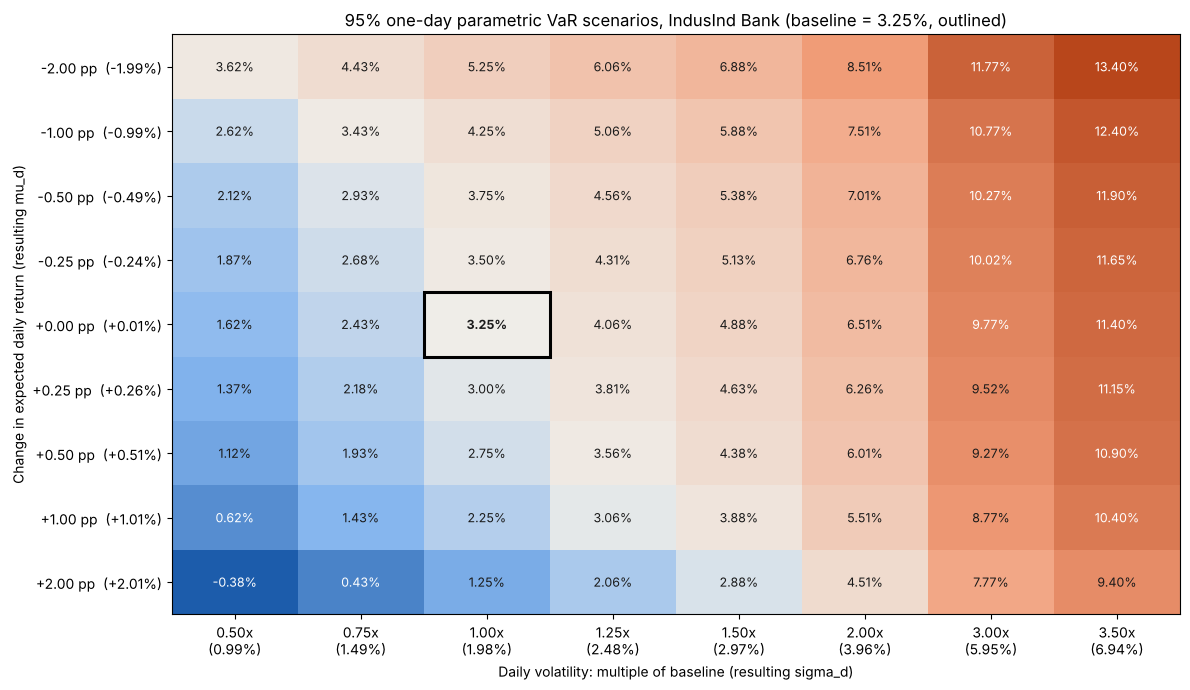

In [12]:
vals = grid.values * 100
cmap = LinearSegmentedColormap.from_list("risk", ["#1c5cab", "#86b6ef", "#efeee9", "#f3a07c", "#b8461b"])
norm = TwoSlopeNorm(vmin=vals.min(), vcenter=var_base * 100, vmax=vals.max())

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(vals, cmap=cmap, norm=norm, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        dark_cell = abs(norm(v) - 0.5) > 0.32
        ax.text(j, i, f"{v:.2f}%", ha="center", va="center", fontsize=9,
                color="white" if dark_cell else "#1a1a1a", fontweight="bold" if (i, j) == (4, 2) else None)
bi, bj = list(mu_shifts).index(0.0), list(vol_mults).index(1.0)
ax.add_patch(plt.Rectangle((bj - 0.5, bi - 0.5), 1, 1, fill=False, ec="black", lw=2.2))
ax.set_xticks(range(len(vol_mults)), [f"{m:.2f}x\n({sig_base*m*100:.2f}%)" for m in vol_mults])
ax.set_yticks(range(len(mu_shifts)), [f"{s*100:+.2f} pp  ({(mu_base+s)*100:+.2f}%)" for s in mu_shifts])
ax.set_xlabel("Daily volatility: multiple of baseline (resulting sigma_d)")
ax.set_ylabel("Change in expected daily return (resulting mu_d)")
ax.set_title(f"95% one-day parametric VaR scenarios, IndusInd Bank (baseline = {var_base*100:.2f}%, outlined)")
plt.tight_layout(); plt.savefig("task6_scenario_heatmap.png", dpi=150); plt.show()

## 10. Sensitivity: change from the baseline and one-way effects

The table gives each cell's change from the baseline VaR (percentage points). The formula is linear in both inputs: $\partial\text{VaR}/\partial\mu_d = -1$ and $\partial\text{VaR}/\partial\sigma_d = z_{0.95} = 1.645$. So a 1 pp fall in the expected return adds 1 pp to VaR, while a 1 pp rise in volatility adds 1.645 pp.

Volatility (x baseline),0.50x,0.75x,1.00x,1.25x,1.50x,2.00x,3.00x,3.50x
Change in expected daily return,,,,,,,,
-2.00 pp,+0.37,+1.18,+2.00,+2.82,+3.63,+5.26,+8.52,+10.15
-1.00 pp,-0.63,+0.18,+1.00,+1.82,+2.63,+4.26,+7.52,+9.15
-0.50 pp,-1.13,-0.32,+0.50,+1.32,+2.13,+3.76,+7.02,+8.65
-0.25 pp,-1.38,-0.57,+0.25,+1.07,+1.88,+3.51,+6.77,+8.40
+0.00 pp,-1.63,-0.82,+0.00,+0.82,+1.63,+3.26,+6.52,+8.15
+0.25 pp,-1.88,-1.07,-0.25,+0.57,+1.38,+3.01,+6.27,+7.90
+0.50 pp,-2.13,-1.32,-0.50,+0.32,+1.13,+2.76,+6.02,+7.65
+1.00 pp,-2.63,-1.82,-1.00,-0.18,+0.63,+2.26,+5.52,+7.15
+2.00 pp,-3.63,-2.82,-2.00,-1.18,-0.37,+1.26,+4.52,+6.15


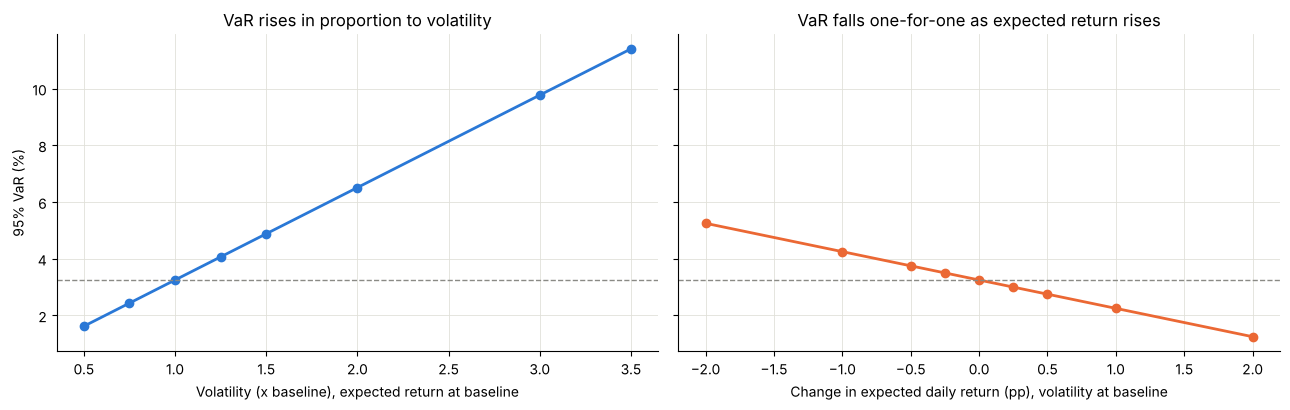

In [13]:
change = (grid - var_base) * 100
display(change.style.format("{:+.2f}").set_caption("Change in 95% VaR vs baseline (percentage points)"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
ax[0].plot(vol_mults, grid.loc["+0.00 pp"].values * 100, marker="o", color=C["hs"], lw=2)
ax[0].set_xlabel("Volatility (x baseline), expected return at baseline"); ax[0].set_ylabel("95% VaR (%)")
ax[0].set_title("VaR rises in proportion to volatility")
ax[1].plot(mu_shifts * 100, grid["1.00x"].values * 100, marker="o", color=C["ph"], lw=2)
ax[1].set_xlabel("Change in expected daily return (pp), volatility at baseline")
ax[1].set_title("VaR falls one-for-one as expected return rises")
for a in ax:
    a.axhline(var_base * 100, color="#8a8a85", ls="--", lw=1); a.grid(color="#e1e0d9", lw=0.6)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 11. Historical reference points for the scenarios

To judge which scenarios are plausible, the table places some real 21-day periods of IndusInd Bank's history on the same axes: their average daily return relative to the baseline mean, their volatility relative to the baseline volatility, and the 95% VaR the formula gives with those inputs. It also lists the largest one-day losses since 2020.

In [14]:
m21 = returns.rolling(21).mean(); s21 = returns.rolling(21).std()
episodes = {
    "Calmest 21 days (lowest volatility)":        s21.idxmin(),
    "Most stressed 21 days (highest volatility)": s21.idxmax(),
    "Worst 21-day average return":                m21.idxmin(),
    "Best 21-day average return":                 m21.idxmax(),
    "Most recent 21 days":                        returns.index[-1],
}
anchors = pd.DataFrame({
    "21 days ending":         [d.date() for d in episodes.values()],
    "mean shift (pp/day)":    [(m21[d] - mu_base) * 100 for d in episodes.values()],
    "vol (x baseline)":       [s21[d] / sig_base for d in episodes.values()],
    "95% VaR with these inputs": [z95 * s21[d] - m21[d] for d in episodes.values()],
}, index=list(episodes.keys()))
display(anchors.style.format({"mean shift (pp/day)": "{:+.2f}", "vol (x baseline)": "{:.2f}x",
                              "95% VaR with these inputs": "{:.2%}"}))

worst = returns.nsmallest(5).to_frame("one-day return")
worst["loss / baseline 95% VaR"] = -worst["one-day return"] / var_base
worst.style.format({"one-day return": "{:.2%}", "loss / baseline 95% VaR": "{:.1f}x"})

,21 days ending,mean shift (pp/day),vol (x baseline),95% VaR with these inputs
Calmest 21 days (lowest volatility),2023-06-08,+0.55,0.34x,0.55%
Most stressed 21 days (highest volatility),2025-04-15,-0.71,3.41x,11.82%
Worst 21-day average return,2025-03-11,-2.14,3.05x,12.07%
Best 21-day average return,2020-12-01,+2.09,1.73x,3.55%
Most recent 21 days,2026-11-12,+0.43,1.09x,3.11%


,one-day return,loss / baseline 95% VaR
Date,,
2025-03-11 00:00:00,-27.16%,8.4x
2024-10-25 00:00:00,-18.63%,5.7x
2021-11-08 00:00:00,-10.76%,3.3x
2024-06-04 00:00:00,-9.03%,2.8x
2021-04-12 00:00:00,-8.58%,2.6x


## 12. Key numbers for the discussion (auto-generated)

In [15]:
imax = np.unravel_index(np.argmax(grid.values), grid.shape)
imin = np.unravel_index(np.argmin(grid.values), grid.shape)
print(f"- Baseline 95% VaR = {var_base*100:.4f}% (matches Task 4).")
print(f"- Highest risk: {grid.index[imax[0]]} and {grid.columns[imax[1]]} volatility -> VaR = {grid.values[imax]*100:.2f}% "
      f"({grid.values[imax]/var_base:.1f}x baseline).")
print(f"- Lowest:       {grid.index[imin[0]]} and {grid.columns[imin[1]]} volatility -> VaR = {grid.values[imin]*100:.2f}%.")
print(f"- Volatility x2 (mean unchanged): {grid.loc['+0.00 pp','2.00x']*100:.2f}% | volatility x0.5: {grid.loc['+0.00 pp','0.50x']*100:.2f}%.")
print(f"- Mean -1 pp (volatility unchanged): {grid.loc['-1.00 pp','1.00x']*100:.2f}% | mean +1 pp: {grid.loc['+1.00 pp','1.00x']*100:.2f}%.")
neg = (grid < 0).sum().sum()
print(f"- Cells with negative VaR (expected gain larger than z*sigma): {neg} -> the formula then reports 'no loss at 95%', "
      "which shows how strongly an assumed positive drift can hide risk.")
print(f"- Largest one-day loss since 2020 = {-returns.min()*100:.1f}% ({returns.idxmin().date()}), "
      f"{-returns.min()/var_base:.1f}x the baseline 95% VaR.")

- Baseline 95% VaR = 3.2495% (matches Task 4).
- Highest risk: -2.00 pp and 3.50x volatility -> VaR = 13.40% (4.1x baseline).
- Lowest:       +2.00 pp and 0.50x volatility -> VaR = -0.38%.
- Volatility x2 (mean unchanged): 6.51% | volatility x0.5: 1.62%.
- Mean -1 pp (volatility unchanged): 4.25% | mean +1 pp: 2.25%.
- Cells with negative VaR (expected gain larger than z*sigma): 1 -> the formula then reports 'no loss at 95%', which shows how strongly an assumed positive drift can hide risk.
- Largest one-day loss since 2020 = 27.2% (2025-03-11), 8.4x the baseline 95% VaR.


In [16]:
# save tables for the report
comparison.to_csv("task6_var_comparison.csv")
grid.to_csv("task6_scenario_grid.csv")